# Statistiques d'image

Une image numérique est un tableau de nombres. Avant de regrouper des pixels comme au [niveau 3](ML_3_apprentissage_non_supervisé_clustering_kmean.ipynb), ou de reconnaître un visage comme au [niveau 4](ML_4_apprentissage_classif_supervisee.ipynb), on lit la répartition de ces nombres.

Ce notebook couvre les statistiques descriptives d'une image — histogramme, moments, entropie, texture locale, plusieurs canaux — puis trois traitements qui s'appuient directement sur l'histogramme : étalement, seuillage, égalisation. Il se termine par des recommandations concrètes pour un usage réel : segmenter des types de forêt dans une orthophoto.

La photo est publique, téléchargée depuis Wikimedia Commons, pour que le notebook s'exécute sans dépôt de fichier.

**Parcours** — les numéros sont ceux des sections.

| Section | Question |
|---|---|
| 1 | Que contient une image en niveaux de gris ? |
| 2 | Que compte un histogramme ? |
| 3 | À quoi servent l'histogramme normalisé et l'histogramme cumulé ? |
| 4 | Que disent la moyenne, l'écart-type et l'asymétrie d'une zone ? |
| 5 | L'entropie ajoute-t-elle quelque chose à l'écart-type ? |
| 6 | Une zone sans fenêtre glissante peut-elle tromper sur sa texture ? |
| 7 | Pourquoi regarder plusieurs canaux à la fois ? |
| 8 | Comment l'étalement rend-il une image peu contrastée lisible ? |
| 9 | Que sépare un seuil ? |
| 10 | Que change l'égalisation d'histogramme ? |
| 11 | Que retenir pour segmenter des types de forêt dans une orthophoto ? |


## 1. Une image est un tableau

Chaque case du tableau est un pixel. En niveaux de gris codés sur 8 bits, cette case vaut un entier de 0 (noir) à 255 (blanc). La **dynamique** est l'écart entre la plus petite et la plus grande valeur réellement présentes.

La photo utilisée est un paysage de la région d'Arnisee. Source : [Landscape Arnisee-region.JPG](https://commons.wikimedia.org/wiki/File:Landscape_Arnisee-region.JPG), Wikimedia Commons. On la convertit en niveaux de gris pour les sections 1 à 6 et 8 à 10 : les trois canaux rouge, vert et bleu deviennent une seule valeur par pixel. La section 7 reviendra sur la version en couleur.


### Installer les dépendances et charger la photo


In [1]:
%pip install -q pillow matplotlib numpy scipy


Note: you may need to restart the kernel to use updated packages.


332 lignes × 500 colonnes, valeurs de 0 à 255


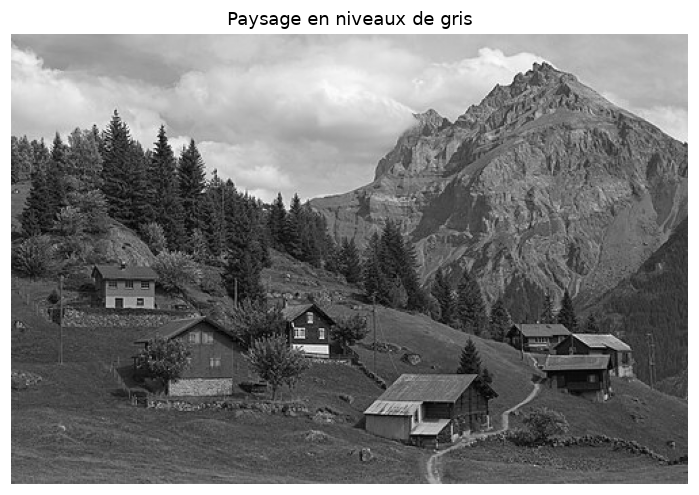

In [2]:
import time
import urllib.request
from io import BytesIO

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from scipy.ndimage import uniform_filter

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

URL_PAYSAGE = (
    "https://upload.wikimedia.org/wikipedia/commons/thumb/"
    "1/14/Landscape_Arnisee-region.JPG/500px-Landscape_Arnisee-region.JPG"
)


def telecharger_image(url, essais=3):
    """Télécharge une photo. Renvoie l'image PIL en couleur."""
    derniere_erreur = None
    for essai in range(essais):
        try:
            requete = urllib.request.Request(
                url, headers={"User-Agent": "statistiques-image/1.0 (educational)"}
            )
            with urllib.request.urlopen(requete, timeout=60) as reponse:
                return Image.open(BytesIO(reponse.read())).convert("RGB")
        except Exception as erreur:
            derniere_erreur = erreur
            time.sleep(1.5 * (essai + 1))
    raise RuntimeError(f"Téléchargement impossible pour {url}") from derniere_erreur


image_couleur_pil = telecharger_image(URL_PAYSAGE)
image = np.asarray(image_couleur_pil.convert("L"))
print(
    f"{image.shape[0]} lignes × {image.shape[1]} colonnes, "
    f"valeurs de {image.min()} à {image.max()}"
)

fig, ax = plt.subplots(figsize=(7.2, 4.6))
ax.imshow(image, cmap="gray", vmin=0, vmax=255)
ax.set_title("Paysage en niveaux de gris")
ax.axis("off")
fig.tight_layout()
plt.show()


### Lire le tableau

`vmin=0` et `vmax=255` fixent le noir et le blanc. Sans eux, Matplotlib étirerait automatiquement le minimum et le maximum de la photo, et l'on croirait l'image plus contrastée qu'elle ne l'est. La dynamique affichée ici est la dynamique réelle : cette photo occupe déjà tout l'intervalle 0–255.


## 2. L'histogramme compte les niveaux

L'histogramme $H(g)$ compte combien de pixels ont le niveau de gris $g$ :

$$
H(g) = \#\{ (i,j) : \mathrm{image}(i,j) = g \}
$$

$g$ va de 0 à 255. La somme des 256 comptes est égale au nombre de pixels. `np.bincount` fait ce comptage d'un coup ; une double boucle sur les lignes et les colonnes ferait le même total, plus lentement.


Somme des comptes : 166000 (nombre de pixels : 166000)
Mode : niveau 75, 2051 pixels


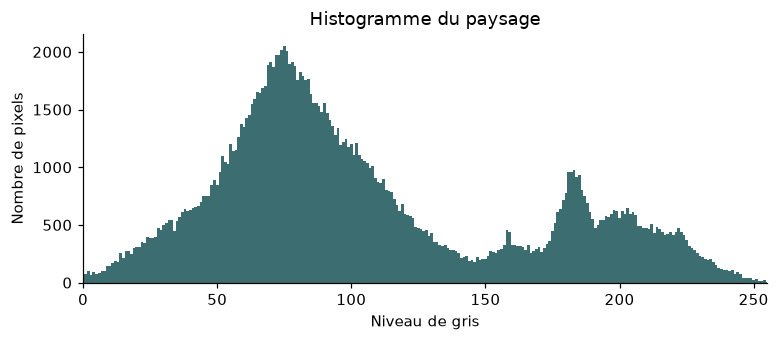

In [3]:
def histogramme(image):
    """Compte le nombre de pixels de chaque niveau de 0 à 255."""
    return np.bincount(image.ravel(), minlength=256)


def afficher_histogramme(comptes, titre, axe_y="Nombre de pixels"):
    fig, ax = plt.subplots(figsize=(7.2, 3.2))
    ax.bar(np.arange(256), comptes, width=1.0, color="#3c6e71")
    ax.set_xlim(0, 255)
    ax.set_xlabel("Niveau de gris")
    ax.set_ylabel(axe_y)
    ax.set_title(titre)
    fig.tight_layout()
    plt.show()


comptes = histogramme(image)
print(f"Somme des comptes : {comptes.sum()} (nombre de pixels : {image.size})")
print(f"Mode : niveau {int(comptes.argmax())}, {int(comptes.max())} pixels")
afficher_histogramme(comptes, "Histogramme du paysage")


### Lire l'histogramme

Le **mode** est le niveau le plus fréquent : ici **75**, avec environ 2 050 pixels. Il correspond aux verts sombres de la forêt et de la prairie, qui occupent une grande partie de la photo.

À droite du mode, les comptes restent élevés jusque vers 180–230. Ce sont les pixels clairs du ciel et de la roche éclairée. Il n'y a pas ici cinq pics séparés (forêt, pelouse, eau, route, bâti) comme sur certaines photos aériennes : le ciel et la roche se recouvrent dans les niveaux clairs, et la forêt et la prairie se recouvrent dans les niveaux sombres. L'histogramme de l'image entière mélange ces zones. Les sections suivantes les séparent, d'abord zone par zone, puis avec d'autres outils que le seul niveau de gris.


## 3. Histogramme normalisé et histogramme cumulé

L'histogramme normalisé est une proportion. $N$ est le nombre de pixels :

$$
p(g) = \frac{H(g)}{N}
$$

L'histogramme cumulé additionne ces proportions du noir jusqu'au niveau $g$ :

$$
F(g) = \sum_{k=0}^{g} p(k)
$$

$F(g)$ est la part des pixels plus sombres ou égaux à $g$. $F(255)$ vaut 1. Cette courbe sert à la section 10, pour l'égalisation.


Somme des proportions : 1.000
Cumul en 255 : 1.000
La moitié des pixels est en dessous du niveau 90


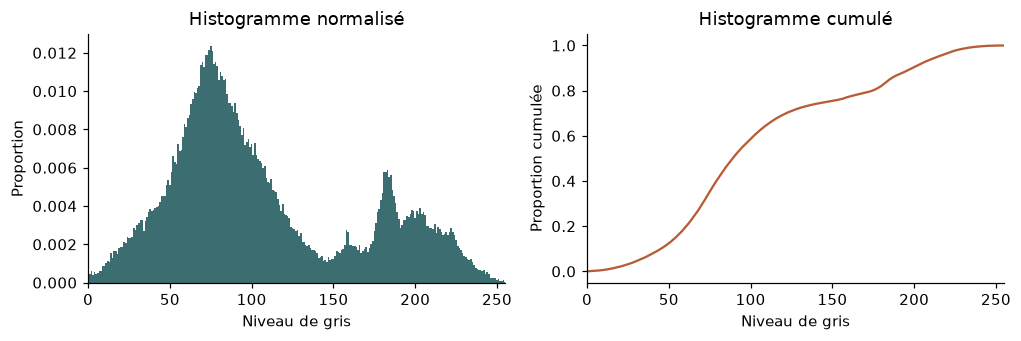

In [4]:
def histogramme_normalise(image):
    """Proportion de pixels à chaque niveau. La somme vaut 1."""
    comptes = histogramme(image).astype(float)
    return comptes / comptes.sum()


def histogramme_cumule(image):
    """Part des pixels de niveau inférieur ou égal à g."""
    return np.cumsum(histogramme_normalise(image))


proportions = histogramme_normalise(image)
cumul = histogramme_cumule(image)
print(f"Somme des proportions : {proportions.sum():.3f}")
print(f"Cumul en 255 : {cumul[-1]:.3f}")
print(f"La moitié des pixels est en dessous du niveau {int(np.searchsorted(cumul, 0.5))}")

fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.2))
axes[0].bar(np.arange(256), proportions, width=1.0, color="#3c6e71")
axes[0].set_title("Histogramme normalisé")
axes[0].set_ylabel("Proportion")
axes[1].plot(cumul, color="#b85c38")
axes[1].set_title("Histogramme cumulé")
axes[1].set_ylabel("Proportion cumulée")
for ax in axes:
    ax.set_xlim(0, 255)
    ax.set_xlabel("Niveau de gris")
fig.tight_layout()
plt.show()


### Lire les deux courbes

L'histogramme normalisé a la même forme que le précédent : seuls les nombres de l'axe vertical ont changé. On peut comparer deux images de tailles différentes, parce que chaque barre est une proportion.

L'histogramme cumulé monte vite autour du mode 75, puis plus lentement dans les niveaux clairs. La moitié des pixels a un niveau inférieur ou égal à **90**. Cette valeur est une médiane : elle ne coïncide pas avec la moyenne, calculée à la section suivante, parce que la distribution n'est pas symétrique.


## 4. Moyenne, écart-type et asymétrie d'une zone

La moyenne et l'écart-type de toute la photo mélangent le ciel, la forêt, la roche et la prairie. On les calcule donc sur quatre rectangles, réutilisés dans tout le reste du notebook.

Le moment d'ordre 1 est la **moyenne** : le niveau typique de la zone.

$$
m = \frac{1}{N} \sum_i x_i
$$

Le moment d'ordre 2, autour de la moyenne, donne l'**écart-type** : l'étalement des niveaux à l'intérieur de la zone. Une zone uniforme a un petit écart-type ; une zone avec des ombres et des surfaces éclairées a un grand écart-type.

$$
s = \sqrt{ \frac{1}{N} \sum_i (x_i - m)^2 }
$$

Le moment d'ordre 3 donne l'**asymétrie**. Négative, la zone a une queue vers les niveaux sombres. Positive, la queue est vers les niveaux clairs. Proche de 0, la répartition est à peu près symétrique.

$$
\gamma = \frac{1}{N s^3} \sum_i (x_i - m)^3
$$


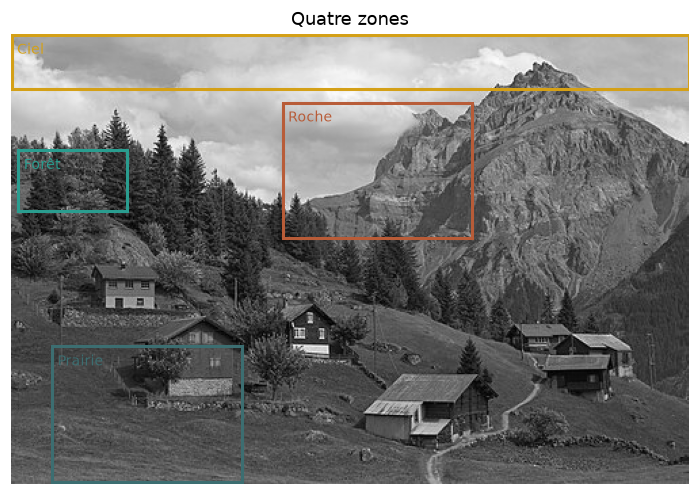

Zone         Moyenne  Écart-type   Asymétrie
Ciel           192.7        28.8       -0.97
Forêt           63.7        28.7        0.54
Roche          137.5        50.2       -0.09
Prairie         79.2        22.7        0.33

Image entière : moyenne 106.7, écart-type 57.1, asymétrie 0.67


In [5]:
zones = {
    "Ciel": (0, 0, image.shape[1], 40),
    "Forêt": (5, 85, 80, 45),
    "Roche": (200, 50, 140, 100),
    "Prairie": (30, 230, 140, 100),
}


def extraire(image, boite):
    """boite = (colonne, ligne, largeur, hauteur), origine en haut à gauche."""
    colonne, ligne, largeur, hauteur = boite
    return image[ligne : ligne + hauteur, colonne : colonne + largeur]


def moments(zone):
    valeurs = zone.astype(float)
    moyenne = valeurs.mean()
    ecart_type = valeurs.std()
    asymetrie = ((valeurs - moyenne) ** 3).mean() / (ecart_type ** 3)
    return moyenne, ecart_type, asymetrie


fig, ax = plt.subplots(figsize=(7.2, 4.6))
ax.imshow(image, cmap="gray", vmin=0, vmax=255)
couleurs_zones = {"Ciel": "#d4a017", "Forêt": "#2a9d8f", "Roche": "#b85c38", "Prairie": "#3c6e71"}
for nom, boite in zones.items():
    colonne, ligne, largeur, hauteur = boite
    rectangle = plt.Rectangle(
        (colonne, ligne), largeur, hauteur, fill=False, edgecolor=couleurs_zones[nom], linewidth=2
    )
    ax.add_patch(rectangle)
    ax.text(colonne + 4, ligne + 14, nom, color=couleurs_zones[nom], fontsize=9)
ax.set_title("Quatre zones")
ax.axis("off")
fig.tight_layout()
plt.show()

print(f"{'Zone':10}{'Moyenne':>10}{'Écart-type':>12}{'Asymétrie':>12}")
for nom, boite in zones.items():
    moyenne, ecart_type, asymetrie = moments(extraire(image, boite))
    print(f"{nom:10}{moyenne:10.1f}{ecart_type:12.1f}{asymetrie:12.2f}")

print(
    f"\nImage entière : moyenne {image.mean():.1f}, "
    f"écart-type {image.std():.1f}, "
    f"asymétrie {moments(image)[2]:.2f}"
)


### Lire les moments

| Zone | Moyenne | Écart-type | Asymétrie | Lecture |
|---|---:|---:|---:|---|
| Ciel | 193 | 29 | −0,97 | Clair. La queue vers le sombre vient des nuages plus gris. |
| Forêt | 64 | 29 | 0,54 | Sombre, avec quelques pixels plus clairs entre les arbres. |
| Roche | 138 | 50 | −0,09 | Ni franchement claire ni franchement sombre, et la plus hétérogène : faces éclairées et ombres. |
| Prairie | 79 | 23 | 0,33 | Sombre comme la forêt, mais plus homogène. |

La moyenne seule ne sépare pas la forêt de la prairie (64 contre 79). L'écart-type les distingue mieux : la prairie est le rectangle le plus régulier. La roche se reconnaît à son grand écart-type, pas à sa moyenne. L'asymétrie du ciel (−0,97) dit que la plupart des pixels sont très clairs et qu'une minorité tire vers le gris.

Sur l'image entière, la moyenne vaut **107** et l'écart-type **57**. Cette moyenne n'est le niveau typique d'aucune des quatre zones : elle est un mélange. C'est pourquoi les moments se calculent sur une zone dont on connaît l'occupation, ou dont on suppose qu'elle est homogène.


## 5. Entropie : une autre mesure de dispersion

L'écart-type mesure l'étalement des niveaux autour de la moyenne. L'**entropie** mesure autre chose : à quel point les niveaux présents sont également répartis, sans référence à une valeur centrale.

$$
E = - \sum_{g : p(g) > 0} p(g) \, \log_2 p(g)
$$

Avec 256 niveaux possibles, l'entropie maximale est $\log_2 256 = 8$ bits, atteinte si tous les niveaux étaient également probables. Une zone qui n'utilise que quelques niveaux, même avec un grand écart-type si ces niveaux sont éloignés, a une entropie plus basse qu'une zone qui utilise beaucoup de niveaux de façon régulière.


In [6]:
def entropie(image):
    """Entropie de Shannon de l'histogramme, en bits."""
    proportions = histogramme_normalise(image)
    proportions = proportions[proportions > 0]
    return -(proportions * np.log2(proportions)).sum()


print(f"Entropie de l'image entière : {entropie(image):.2f} bits (maximum possible : 8,00)")
print(f"\n{'Zone':10}{'Écart-type':>12}{'Entropie':>12}")
for nom, boite in zones.items():
    zone = extraire(image, boite)
    print(f"{nom:10}{zone.std():12.1f}{entropie(zone):12.2f}")


Entropie de l'image entière : 7.57 bits (maximum possible : 8,00)

Zone        Écart-type    Entropie
Ciel              28.8        6.62
Forêt             28.7        6.80
Roche             50.2        7.43
Prairie           22.7        6.44


### Lire l'entropie

| Zone | Écart-type | Entropie (bits) |
|---|---:|---:|
| Ciel | 29 | 6,62 |
| Forêt | 29 | 6,80 |
| Roche | 50 | 7,43 |
| Prairie | 23 | 6,44 |

La roche a l'écart-type et l'entropie les plus élevés des quatre zones : les deux mesures s'accordent, parce que ses ombres et ses faces éclairées étalent vraiment les niveaux sur une large plage, utilisée de façon assez régulière.

Le ciel et la forêt ont presque le même écart-type (29), mais une entropie différente (6,62 contre 6,80). Le ciel est dominé par un dégradé de blancs et de gris clairs peu nombreux, assez concentrés sur quelques niveaux hauts ; la forêt mélange beaucoup de petites variations de vert sombre entre feuillages et ombres, réparties sur davantage de niveaux distincts. L'écart-type ne voit que l'étalement global ; l'entropie est sensible à cette différence de répartition interne, même quand l'étalement global se ressemble.


## 6. Statistiques locales : la texture au-delà de la zone

Les moments de la section 4 résument chaque zone par un seul nombre. Mais à l'intérieur même de la forêt, certains pixels sont des feuillages éclairés et d'autres des ombres entre les branches : il y a une structure fine, une **texture**, que la moyenne et l'écart-type de toute la zone ne montrent pas pixel par pixel.

L'écart-type local recalcule l'écart-type dans une petite fenêtre glissante, centrée sur chaque pixel. Avec le résultat $E[X^2] - (E[X])^2$, il se calcule rapidement par deux moyennes glissantes, sans boucle sur chaque pixel.


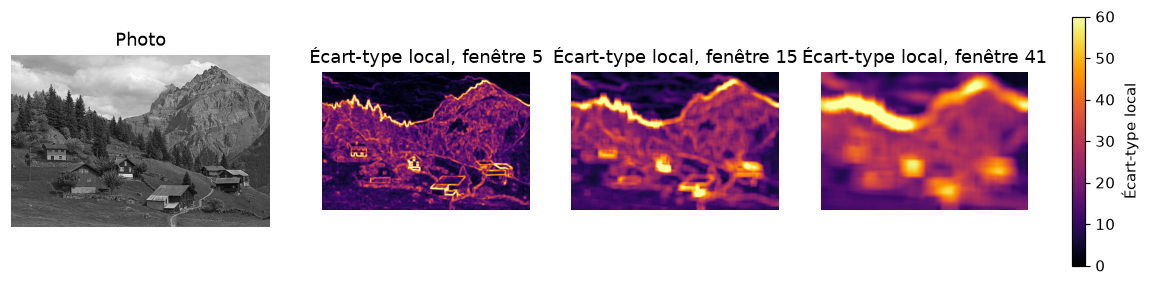

Zone        fenêtre 5  fenêtre 15  fenêtre 41
Ciel              4.8         9.5        17.1
Forêt            21.7        25.9        34.4
Roche            13.5        20.5        30.9
Prairie          12.6        15.5        18.7


In [7]:
def moyenne_locale(image, taille):
    """Moyenne dans une fenêtre carrée de côté `taille`, centrée sur chaque pixel."""
    return uniform_filter(image.astype(float), size=taille, mode="reflect")


def ecart_type_local(image, taille):
    """Écart-type local, via E[X²] - (E[X])²."""
    moyenne = moyenne_locale(image, taille)
    moyenne_des_carres = moyenne_locale(image.astype(float) ** 2, taille)
    variance = np.clip(moyenne_des_carres - moyenne ** 2, 0, None)
    return np.sqrt(variance)


fig, axes = plt.subplots(1, 4, figsize=(14, 4.2))
axes[0].imshow(image, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Photo")
cartes_texture = {}
for ax, taille in zip(axes[1:], (5, 15, 41)):
    carte = ecart_type_local(image, taille)
    cartes_texture[taille] = carte
    im = ax.imshow(carte, cmap="inferno", vmin=0, vmax=60)
    ax.set_title(f"Écart-type local, fenêtre {taille}")
for ax in axes:
    ax.axis("off")
fig.colorbar(im, ax=axes[1:].tolist(), shrink=0.7, label="Écart-type local")
plt.show()

print(f"{'Zone':10}{'fenêtre 5':>11}{'fenêtre 15':>12}{'fenêtre 41':>12}")
for nom, boite in zones.items():
    colonne, ligne, largeur, hauteur = boite
    valeurs = [
        extraire(cartes_texture[t], boite).mean() for t in (5, 15, 41)
    ]
    print(f"{nom:10}{valeurs[0]:11.1f}{valeurs[1]:12.1f}{valeurs[2]:12.1f}")


### Lire la texture locale

| Zone | fenêtre 5 | fenêtre 15 | fenêtre 41 |
|---|---:|---:|---:|
| Ciel | 4,8 | 9,5 | 17,1 |
| Forêt | 21,7 | 25,9 | 34,4 |
| Roche | 13,5 | 20,5 | 30,9 |
| Prairie | 12,6 | 15,5 | 18,7 |

À chaque taille de fenêtre, la forêt a la texture locale la plus élevée des quatre zones — alors que son écart-type global (section 4) n'était pas le plus élevé. C'est tout l'intérêt de la mesure locale : la forêt varie beaucoup d'un pixel à son voisin immédiat (feuillage éclairé contre ombre entre les branches), plus que le ciel, dont l'écart-type global venait surtout d'un dégradé doux entre le haut et le bas de l'image, pas d'une variation pixel à pixel.

L'écart entre la forêt et la roche se resserre nettement quand la fenêtre grandit : de **8,2** points à fenêtre 5 (21,7 contre 13,5) à seulement **3,5** points à fenêtre 41 (34,4 contre 30,9). Sur la carte à fenêtre 41, la silhouette de la montagne et ses grandes zones d'ombre deviennent elles-mêmes « texturées » à cette échelle, parce que la fenêtre est assez large pour capter leurs variations de relief à grande échelle, pas seulement la texture fine du feuillage. Une fenêtre trop petite capte surtout du bruit pixel à pixel ; une fenêtre trop grande mélange des classes différentes au voisinage d'une frontière et fait apparaître une texture qui n'est due qu'à l'échelle du relief. On observe aussi, sur les trois cartes, des points très lumineux sur les toits des chalets : la texture locale réagit à n'importe quel contour net, pas seulement à la végétation.


## 7. Plusieurs canaux : corrélation et indice de végétation

Jusqu'ici, un pixel n'avait qu'une valeur. Une photo couleur en a trois : rouge, vert, bleu. On revient à l'image en couleur pour cette section.


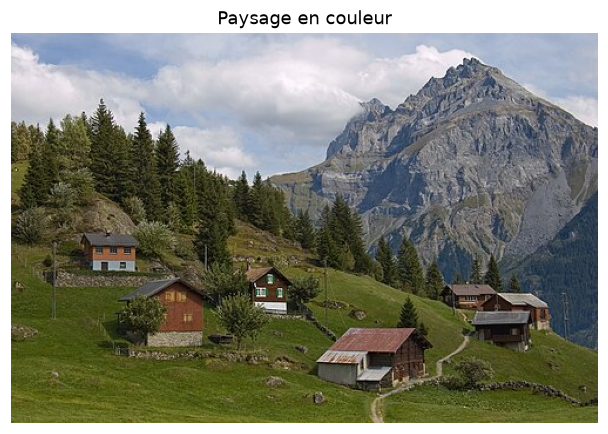

Corrélation entre canaux (Rouge, Vert, Bleu) :
[[1.    0.985 0.912]
 [0.985 1.    0.932]
 [0.912 0.932 1.   ]]

Zone         Rouge    Vert    Bleu
Ciel         185.8   192.7   210.5
Forêt         68.7    66.6    36.3
Roche        132.3   138.2   147.5
Prairie       84.0    86.1    31.7


In [8]:
image_couleur = np.asarray(image_couleur_pil).astype(float)
rouge, vert, bleu = image_couleur[:, :, 0], image_couleur[:, :, 1], image_couleur[:, :, 2]

fig, ax = plt.subplots(figsize=(7.2, 4.6))
ax.imshow(image_couleur.astype(np.uint8))
ax.set_title("Paysage en couleur")
ax.axis("off")
plt.show()

pixels = image_couleur.reshape(-1, 3)
correlation = np.corrcoef(pixels.T)
print("Corrélation entre canaux (Rouge, Vert, Bleu) :")
print(np.round(correlation, 3))

print(f"\n{'Zone':10}{'Rouge':>8}{'Vert':>8}{'Bleu':>8}")
for nom, boite in zones.items():
    moyennes = extraire(image_couleur, boite).reshape(-1, 3).mean(axis=0)
    print(f"{nom:10}{moyennes[0]:8.1f}{moyennes[1]:8.1f}{moyennes[2]:8.1f}")


### Lire la corrélation entre canaux

Les trois canaux sont très corrélés entre eux : 0,985 entre rouge et vert, 0,932 entre vert et bleu, 0,912 entre rouge et bleu. Sur une photo en lumière naturelle, un pixel plus clair l'est presque toujours dans les trois couleurs à la fois — c'est l'éclairage qui varie le plus, pas la teinte. Les trois bandes transportent donc en grande partie la même information : la luminosité. Utiliser les trois canaux bruts comme s'ils étaient trois mesures indépendantes ajoute surtout de la redondance.

Ce qui différencie vraiment les quatre zones n'est pas la quantité de lumière, mais la proportion de vert par rapport au rouge et au bleu. C'est ce qu'un **indice de végétation** calcule.


Zone           ExG    GRVI
Ciel         -10.9   0.022
Forêt         28.2  -0.016
Roche         -3.4   0.030
Prairie       56.5   0.017


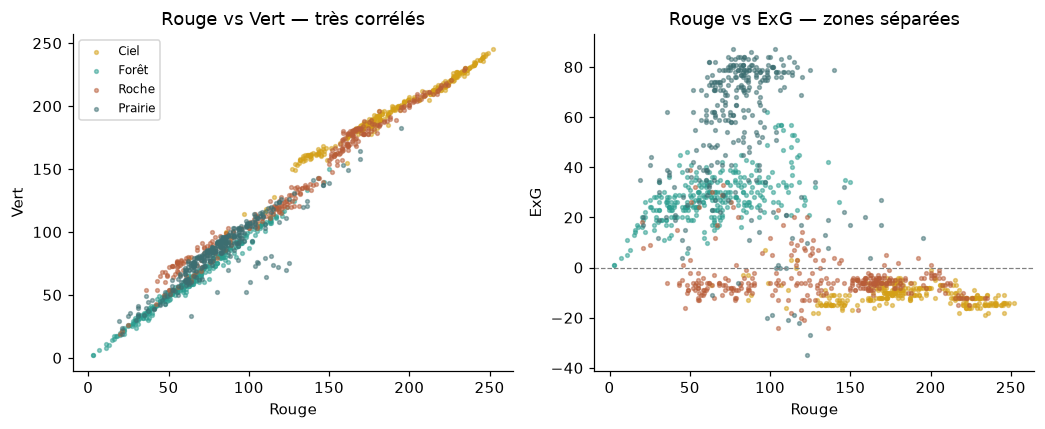

In [9]:
def exces_de_vert(rouge, vert, bleu):
    """ExG = 2×vert − rouge − bleu. Positif pour une surface dominée par le vert."""
    return 2 * vert - rouge - bleu


def indice_vert_rouge(rouge, vert):
    """GRVI = (vert − rouge) / (vert + rouge)."""
    return (vert - rouge) / (vert + rouge + 1e-6)


exg = exces_de_vert(rouge, vert, bleu)
grvi = indice_vert_rouge(rouge, vert)

print(f"{'Zone':10}{'ExG':>8}{'GRVI':>8}")
for nom, boite in zones.items():
    z_exg = extraire(exg, boite).mean()
    z_grvi = extraire(grvi, boite).mean()
    print(f"{nom:10}{z_exg:8.1f}{z_grvi:8.3f}")

rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, 2, figsize=(9.6, 4))
for nom, boite in zones.items():
    colonne, ligne, largeur, hauteur = boite
    zr = extraire(rouge, boite).ravel()
    zv = extraire(vert, boite).ravel()
    ze = extraire(exg, boite).ravel()
    echantillon = rng.choice(len(zr), size=min(300, len(zr)), replace=False)
    axes[0].scatter(zr[echantillon], zv[echantillon], s=6, alpha=0.5, color=couleurs_zones[nom], label=nom)
    axes[1].scatter(zr[echantillon], ze[echantillon], s=6, alpha=0.5, color=couleurs_zones[nom], label=nom)
axes[0].set_xlabel("Rouge")
axes[0].set_ylabel("Vert")
axes[0].set_title("Rouge vs Vert — très corrélés")
axes[0].legend(fontsize=8)
axes[1].set_xlabel("Rouge")
axes[1].set_ylabel("ExG")
axes[1].set_title("Rouge vs ExG — zones séparées")
axes[1].axhline(0, color="gray", linewidth=0.8, linestyle="--")
fig.tight_layout()
plt.show()


### Lire l'indice de végétation

| Zone | ExG | GRVI |
|---|---:|---:|
| Ciel | −10,9 | 0,022 |
| Forêt | 28,2 | −0,016 |
| Roche | −3,4 | 0,030 |
| Prairie | 56,5 | 0,017 |

Le graphique de gauche confirme la corrélation : les quatre zones s'alignent sur la même diagonale rouge–vert, seulement décalées selon leur luminosité. Dans ce graphique, une zone claire (le ciel) et une zone sombre (la forêt) sont loin l'une de l'autre seulement parce qu'elles sont plus ou moins lumineuses, pas parce que leur couleur diffère.

Le graphique de droite, avec l'ExG en ordonnée, sépare nettement la forêt et la prairie (positives, au-dessus de la ligne pointillée) du ciel et de la roche (négatives ou proches de 0), quelle que soit leur luminosité. L'ExG a été conçu pour cela : en combinant les trois canaux par une soustraction, il retire une grande partie de l'effet de l'éclairage et met en évidence la dominance du vert, propre à la végétation.

Le GRVI, un indice voisin, donne ici des valeurs proches de 0 pour les quatre zones, y compris une valeur légèrement négative pour la forêt : il ne sépare pas la végétation du reste sur cette photo. Deux indices construits avec la même logique — comparer le vert aux autres couleurs — peuvent donc se comporter très différemment selon la teinte exacte de la végétation et les ombres. Aucun indice calculé sur les seules couleurs visibles n'est fiable à lui seul ; un indice comme le NDVI, qui utilise aussi le proche infrarouge, sépare généralement mieux la végétation, mais demande que cette bande soit disponible — ce qui n'est pas le cas de cette photo grand public.


## 8. Dynamique et étalement

L'étalement linéaire étire un intervalle de niveaux $[a, b]$ sur tout l'intervalle 0–255 :

$$
s(x) = 255 \times \frac{x - a}{b - a}
$$

Les valeurs en dehors de $[a, b]$ sont ramenées à 0 ou à 255.

Cette photo occupe déjà 0–255. L'étaler entre son minimum et son maximum ne change donc rien. Le cas utile est une image dont les valeurs sont tassées, comme une bande satellite brute qui n'utilise qu'une petite partie des 256 niveaux. On fabrique ici cette situation en comprimant la photo dans l'intervalle 40–80, puis on l'étale.


Comprimée : 40–80, écart-type 9.0
Étalée    : 0–255, écart-type 57.1


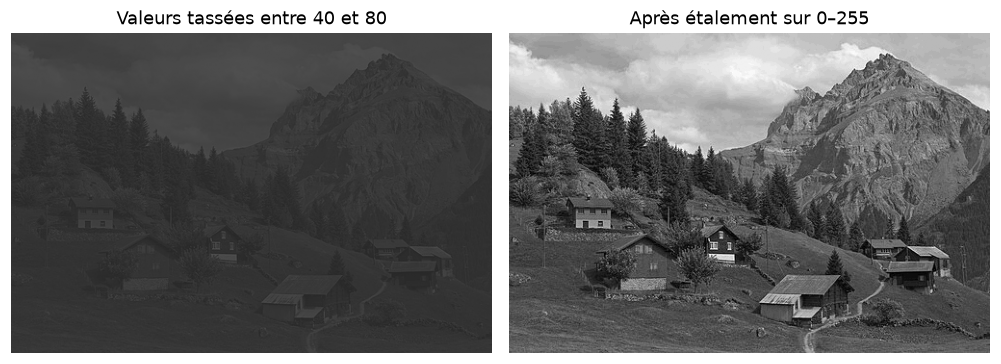

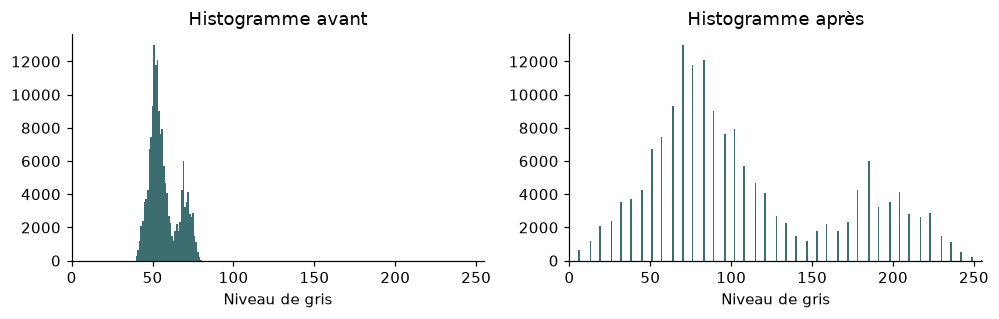

In [10]:
def etaler(image, borne_min, borne_max):
    """Étire [borne_min, borne_max] sur 0–255."""
    etalee = (image.astype(float) - borne_min) / (borne_max - borne_min) * 255
    return np.clip(np.rint(etalee), 0, 255).astype(np.uint8)


comprimee = np.clip(np.rint(image / 255 * 40 + 40), 0, 255).astype(np.uint8)
etalee = etaler(comprimee, int(comprimee.min()), int(comprimee.max()))

print(
    f"Comprimée : {comprimee.min()}–{comprimee.max()}, "
    f"écart-type {comprimee.std():.1f}"
)
print(
    f"Étalée    : {etalee.min()}–{etalee.max()}, "
    f"écart-type {etalee.std():.1f}"
)

fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.6))
axes[0].imshow(comprimee, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Valeurs tassées entre 40 et 80")
axes[1].imshow(etalee, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Après étalement sur 0–255")
for ax in axes:
    ax.axis("off")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.0))
axes[0].bar(np.arange(256), histogramme(comprimee), width=1.0, color="#3c6e71")
axes[0].set_title("Histogramme avant")
axes[1].bar(np.arange(256), histogramme(etalee), width=1.0, color="#3c6e71")
axes[1].set_title("Histogramme après")
for ax in axes:
    ax.set_xlim(0, 255)
    ax.set_xlabel("Niveau de gris")
fig.tight_layout()
plt.show()


### Lire l'étalement

Avant, l'écart-type vaut **9** et l'histogramme est un bloc étroit autour de 56 : l'image paraît grise, presque sans relief, alors que `vmin` et `vmax` montrent le vrai codage 0–255.

Après, la dynamique est de nouveau **0–255** et l'écart-type revient à **57**, celui de la photo d'origine. L'étalement n'invente pas de détail : il espace des niveaux qui étaient collés. Les rapports entre pixels sont conservés, puisque la transformation est linéaire. Choisir $a$ et $b$ plus serrés que le minimum et le maximum écrête les extrêmes et augmente encore le contraste du reste.


## 9. Seuillage

Un seuil coupe les niveaux en deux classes. Ici, un pixel devient blanc s'il est au moins égal à 120, noir sinon.

$$
b(x) = \begin{cases} 255 & \text{si } x \ge 120 \\ 0 & \text{sinon} \end{cases}
$$

120 est au-dessus du mode 75 et de la médiane 90. Il vise les surfaces claires.


Part de pixels ≥ 120 : 31 %


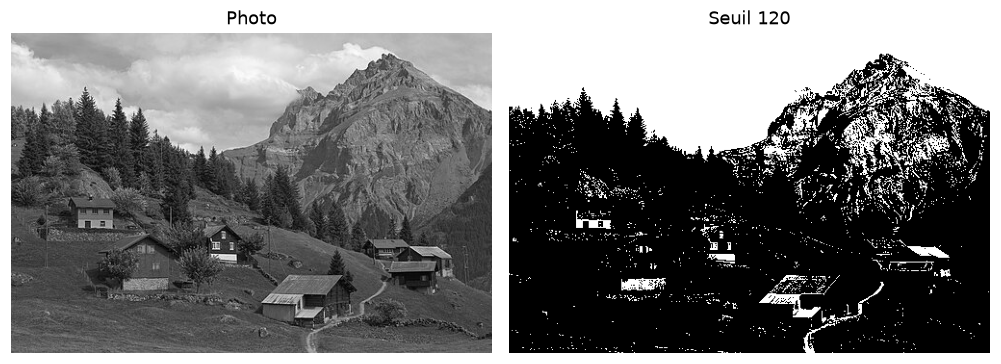

In [11]:
def seuiller(image, seuil):
    """Blanc si le pixel atteint le seuil, noir sinon."""
    return np.where(image >= seuil, np.uint8(255), np.uint8(0))


seuil = 120
masque = seuiller(image, seuil)
print(f"Part de pixels ≥ {seuil} : {100 * (masque == 255).mean():.0f} %")

fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.6))
axes[0].imshow(image, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Photo")
axes[1].imshow(masque, cmap="gray", vmin=0, vmax=255)
axes[1].set_title(f"Seuil {seuil}")
for ax in axes:
    ax.axis("off")
fig.tight_layout()
plt.show()


### Lire le seuil

Environ **31 %** des pixels passent le seuil. Sur l'image binaire, le ciel, la neige et les faces claires de la montagne sont blancs. La forêt et la prairie sont noires. Les toits et les murs clairs des chalets passent aussi le seuil, alors qu'ils ne sont pas du ciel.

Le seuil regroupe des niveaux, pas des objets. Deux surfaces éloignées dans la photo partagent la même classe dès qu'elles ont une valeur proche. C'est le même constat que le regroupement des couleurs au niveau 3, réduit ici à un seul seuil sur un seul canal.


## 10. Égalisation d'histogramme

L'étalement est linéaire. L'égalisation utilise l'histogramme cumulé pour répartir les pixels sur toute la dynamique. Le nouveau niveau d'un pixel de valeur $g$ est :

$$
e(g) = \mathrm{arrondi}\big(255 \times F(g)\big)
$$

Les niveaux rares restent rares en effectif, mais les niveaux fréquents sont écartés les uns des autres. Les zones sombres très peuplées, autour du mode, gagnent du contraste.


Avant : moyenne 107, écart-type 57
Après : moyenne 128, écart-type 73


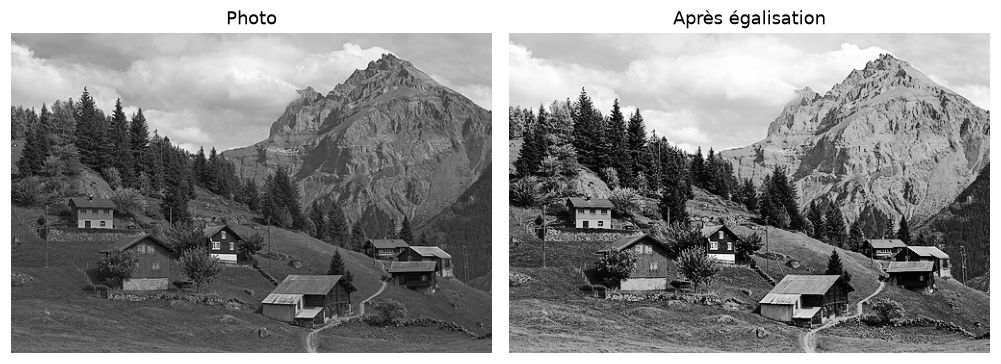

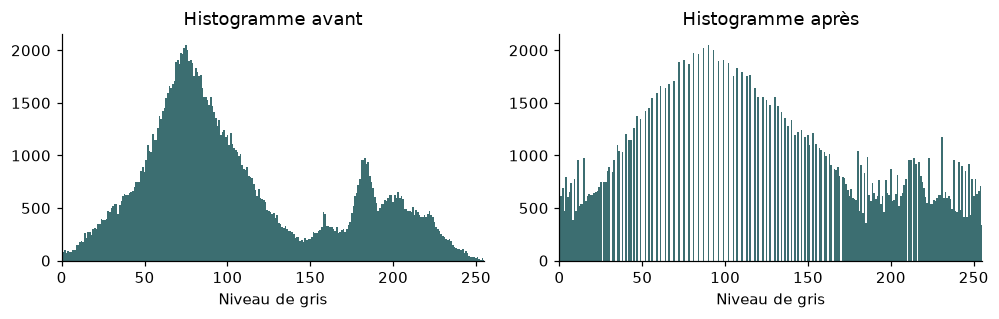

In [12]:
def egaliser(image):
    """Remplace chaque niveau g par 255 fois la proportion de pixels ≤ g."""
    cumul = histogramme_cumule(image)
    egalisee = np.rint(255 * cumul[image])
    return np.clip(egalisee, 0, 255).astype(np.uint8)


egalisee = egaliser(image)
print(
    f"Avant : moyenne {image.mean():.0f}, écart-type {image.std():.0f}"
)
print(
    f"Après : moyenne {egalisee.mean():.0f}, écart-type {egalisee.std():.0f}"
)

fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.6))
axes[0].imshow(image, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Photo")
axes[1].imshow(egalisee, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Après égalisation")
for ax in axes:
    ax.axis("off")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.0))
axes[0].bar(np.arange(256), histogramme(image), width=1.0, color="#3c6e71")
axes[0].set_title("Histogramme avant")
axes[1].bar(np.arange(256), histogramme(egalisee), width=1.0, color="#3c6e71")
axes[1].set_title("Histogramme après")
for ax in axes:
    ax.set_xlim(0, 255)
    ax.set_xlabel("Niveau de gris")
fig.tight_layout()
plt.show()


### Lire l'égalisation

La moyenne passe de **107** à **128**, et l'écart-type de **57** à **73**. L'image occupe mieux les niveaux clairs et les niveaux sombres : la forêt et la prairie se séparent davantage à l'œil, et les ombres de la roche se creusent.

L'histogramme après égalisation n'est pas plat. Tous les pixels qui valaient 75 reçoivent le même nouveau niveau, donc le pic du mode se déplace mais ne disparaît pas. L'égalisation écarte les niveaux entre eux ; elle ne peut pas donner des valeurs différentes à des pixels qui étaient identiques.

Elle n'est pas non plus une correction physique. Une valeur égalisée ne se compare plus à celle d'une autre date ou d'une autre photo : la transformation dépend de l'histogramme de cette image-ci. C'est le point de départ de la section suivante.


## 11. Bilan — segmenter des types de forêt dans une orthophoto

Les sections précédentes ont vu chaque outil séparément, sur une seule photo de paysage. Cette section les remet en ordre pour une tâche réelle : à partir d'une orthophoto (RGB, parfois RGB + proche infrarouge), produire une carte des types de forêt — par exemple feuillu / conifère, ou forêt dense / forêt claire / non-forêt.

### Ce que chaque outil apporte, et ses limites

| Outil (section) | Rôle utile | À éviter |
|---|---|---|
| Histogramme, histogramme cumulé (2, 3) | Vérifier la dynamique de chaque bande avant tout traitement : image sous-exposée, saturée, ou bien calibrée | Juger une classification directement sur l'histogramme global : il mélange toutes les classes |
| Moyenne, écart-type, asymétrie par zone (4) | Caractériser une zone d'entraînement connue (un polygone de forêt de référence, par exemple) | Résumer toute l'image par un seul triplet : la moyenne globale ne correspond à aucune classe réelle |
| Entropie (5) | Repérer une zone dont les niveaux sont répartis de façon homogène ou au contraire concentrés, en complément de l'écart-type | Remplacer l'écart-type : les deux mesures répondent à des questions différentes, aucune ne suffit seule |
| Écart-type local, fenêtre glissante (6) | Construire une carte de texture : sépare les surfaces lisses (eau, champs rasés, ciel) des surfaces texturées (canopée, bâti) | Choisir une fenêtre sans rapport avec la taille des houppiers à la résolution de l'orthophoto ; une fenêtre trop grande mélange les classes à leurs frontières, comme mesuré en section 6 |
| Corrélation entre canaux, indices de végétation (7) | Réduire la redondance entre bandes très corrélées ; calculer un indice qui isole la couleur de la luminosité | Faire confiance à un seul indice visible sans vérification : certains séparent mal selon l'essence et l'éclairage, comme le GRVI ici |
| Étalement linéaire (8) | Prétraitement radiométrique reproductible, applicable de façon identique à toute une mosaïque ou à plusieurs dates | — |
| Seuillage brut (9) | Masque binaire simple : forêt / non-forêt, ou eau, sur une bande bien choisie | Distinguer plusieurs types de forêt avec un seul seuil sur un seul canal : un seuil sépare des niveaux, pas des essences |
| Égalisation d'histogramme (10) | Améliorer la lecture visuelle d'une image, pour la photo-interprétation | Prétraiter des images avant un modèle automatique ou avant de comparer plusieurs tuiles ou dates : la transformation dépend de l'histogramme de chaque image, donc n'est plus comparable d'une image à l'autre |

### Un pipeline recommandé

1. **Contrôler la radiométrie** de l'orthophoto avec l'histogramme de chaque bande (section 2). Corriger par un étalement linéaire si besoin, appliqué avec les mêmes bornes sur toute la mosaïque — jamais par une égalisation, qui romprait la comparabilité entre tuiles.
2. **Construire un tableau de variables par pixel** (ou par petit groupe de pixels) : les bandes brutes disponibles, un indice de végétation si une bande proche infrarouge existe (NDVI), sinon un indice visible testé sur plusieurs candidats comme en section 7, et une texture locale (section 6) avec une fenêtre dimensionnée sur la taille réelle des houppiers compte tenu de la résolution au sol de l'orthophoto.
3. **Choisir la méthode selon les données disponibles** :
   - des polygones de référence existent (inventaire forestier, relevé de terrain) → une approche supervisée comme au [niveau 4](ML_4_apprentissage_classif_supervisee.ipynb). Une forêt aléatoire est un choix par défaut raisonnable sur ce type de variables mélangées et corrélées, avec les mêmes réflexes déjà vus : choisir les hyperparamètres par validation croisée, puis évaluer une seule fois sur un jeu de test séparé — si possible, des parcelles entières plutôt que des pixels isolés, pour éviter qu'un pixel de test soit voisin immédiat d'un pixel d'entraînement.
   - aucune référence n'existe → une approche non supervisée comme au [niveau 3](ML_3_apprentissage_non_supervisé_clustering_kmean.ipynb). Les k-moyennes supposent des groupes ronds et de taille comparable ; la texture et les indices de végétation ne forment pas nécessairement ce genre de groupes, donc les résultats doivent être vérifiés visuellement, pas seulement par l'inertie.
4. **Lire les résultats par classe**, pas seulement une exactitude globale : comme au niveau 2 avec le mIoU, et au niveau 4 avec le F1 macro, une essence rare dans le paysage peut disparaître derrière un bon score global dominé par l'essence la plus fréquente.

### Ce que ce notebook ne remplace pas

Les quatre zones de ce notebook sont choisies à la main sur une seule photo. Une vraie carte forestière demande des polygones de référence couvrant plusieurs placettes, si possible plusieurs dates ou conditions d'éclairage, et un jeu de test qui ne partage pas de pixels voisins avec l'entraînement. Les indices de végétation visibles restent un pis-aller : une bande proche infrarouge, quand elle est disponible, sépare en général mieux les types de végétation que n'importe quelle combinaison de rouge, de vert et de bleu.


### Sources

- Photo : [Landscape Arnisee-region.JPG](https://commons.wikimedia.org/wiki/File:Landscape_Arnisee-region.JPG), Wikimedia Commons.
- Les mêmes opérations dans scikit-image : [`rescale_intensity`](https://scikit-image.org/docs/stable/api/skimage.exposure.html#skimage.exposure.rescale_intensity) pour l'étalement, [`equalize_hist`](https://scikit-image.org/docs/stable/api/skimage.exposure.html#skimage.exposure.equalize_hist) pour l'égalisation, [`filters.rank.entropy`](https://scikit-image.org/docs/stable/api/skimage.filters.rank.html#skimage.filters.rank.entropy) pour une entropie locale, non calculée ici.
- Indices de végétation visibles : Excess Green (Woebbecke et al., 1995), GRVI (Tucker, 1979 pour le principe, décliné en version visible).

### Limites

Les rectangles sont choisis à la main sur cette photo. Un autre cadrage changerait les moyennes. Le seuil 120 et les tailles de fenêtre (5, 15, 41) sont choisis après avoir vu les résultats sur cette image précise ; une autre photo, une autre résolution ou une autre essence demanderaient de les revoir. L'image comprimée de la section 8 est construite pour l'exercice : une bande satellite réelle a en plus du bruit, un calibrage et des valeurs hors de l'échelle 8 bits.
